In [1]:
!pip install statsmodels pandas numpy matplotlib seaborn

=== Descriptive Statistics ===
          Year  GDP_Growth_Pct  Inflation_Rate_Pct  Interest_Rate_Pct  \
count    17.00           17.00               17.00              17.00   
mean   2018.00            6.36                4.07               5.96   
std       5.05            1.33                1.27               1.23   
min    2010.00            4.58                2.23               4.14   
25%    2014.00            5.23                3.00               5.04   
50%    2018.00            6.00                4.16               5.98   
75%    2022.00            7.43                4.96               6.74   
max    2026.00            8.38                6.74               7.88   

       Fiscal_Deficit_GSDP  
count                17.00  
mean                  4.23  
std                   1.10  
min                   2.66  
25%                   3.45  
50%                   3.86  
75%                   5.31  
max                   5.79  

=== OLS Regression Summary ===
                  

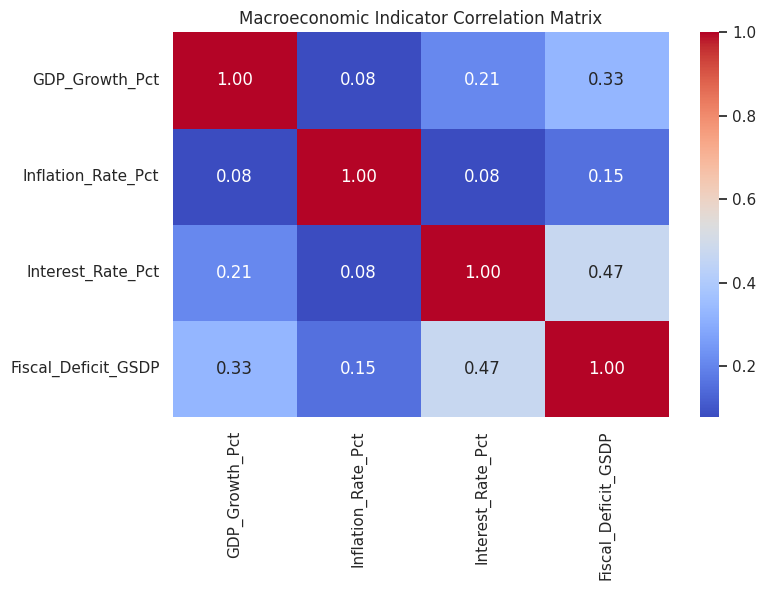

In [2]:
import pandas as pd
import numpy as np
import statsmodels.api as sm
import matplotlib.pyplot as plt
import seaborn as sns

# Set visual theme
sns.set_theme(style="whitegrid")

# 1. Simulate / Load Macroeconomic Panel Dataset (e.g., Indian/Global indicators)
np.random.seed(42)
years = range(2010, 2027)
data = {
    "Year": list(years),
    "GDP_Growth_Pct": np.random.uniform(4.5, 8.5, len(years)),
    "Inflation_Rate_Pct": np.random.uniform(2.0, 7.0, len(years)),
    "Interest_Rate_Pct": np.random.uniform(4.0, 8.0, len(years)),
    "Fiscal_Deficit_GSDP": np.random.uniform(2.5, 6.0, len(years))
}

df = pd.DataFrame(data)

# 2. Summary Statistics
print("=== Descriptive Statistics ===")
print(df.describe().round(2))

# 3. Feature Engineering: Lagged Inflation
df["Inflation_Lag1"] = df["Inflation_Rate_Pct"].shift(1)
df = df.dropna()

# 4. Econometric Specification: Ordinary Least Squares (OLS) Regression
# Dependent Variable (y): GDP Growth Pct
# Independent Variables (X): Inflation, Interest Rate, Fiscal Deficit, Lagged Inflation
X = df[["Inflation_Rate_Pct", "Interest_Rate_Pct", "Fiscal_Deficit_GSDP", "Inflation_Lag1"]]
X = sm.add_constant(X)
y = df["GDP_Growth_Pct"]

ols_model = sm.OLS(y, X).fit()
print("\n=== OLS Regression Summary ===")
print(ols_model.summary())

# 5. Data Visualization: Correlation Heatmap
plt.figure(figsize=(8, 5))
sns.heatmap(df[["GDP_Growth_Pct", "Inflation_Rate_Pct", "Interest_Rate_Pct", "Fiscal_Deficit_GSDP"]].corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Macroeconomic Indicator Correlation Matrix")
plt.show()